In [122]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.preprocessing as prep
from narwhals import Int64


In [162]:
df = pd.read_excel('/Users/ashish/Downloads/IPL Dataset.xlsm')
df.head(5)

,Jersey No,Player,Matches,Inns,Not Out,Runs,Highest Score,Avg,Balls faced,Strike rate,100,50,4s,6s
0,1,KL Rahul,14,14,2,670,132*,55.83,518,129.34,1,5,58,23
1,2,Shikhar Dhawan,17,17,3,618,106*,44.14,427,144.73,2,4,67,12
2,3,David Warner,16,16,2,548,85*,39.14,407,134.64,0,4,52,14
3,4,Shreyas Iyer,17,17,2,519,88*,34.60,421,123.27,0,3,40,16
4,5,Ishan Kishan,14,13,4,516,99,57.33,354,145.76,0,4,36,30


In [124]:
#Q1. What is the maximum number of matches played by an individual player in a season? Print the player name along with the number of matched played.


In [148]:
max_matches = df['Matches'].max()
Q1 = df.loc[df['Matches'] == max_matches][['Player','Matches']]
print(Q1)

            Player  Matches
1   Shikhar Dhawan       17
3     Shreyas Iyer       17
19  Marcus Stoinis       17
67   Kagiso Rabada       17


In [126]:
#Q2. Top 2 players with maximum Average who have scored atleast 2 half centuries ?

In [127]:
Q2 = df[df[50] >= 2].sort_values('Avg', ascending=False).head(2)

print(Q2[['Player', 'Avg', 50]])


             Player    Avg  50
36  Wriddhiman Saha  71.33   2
4      Ishan Kishan  57.33   4


In [128]:
#Q3. Create 2 new columns based on Player name. First column will have first name and second column will have last name. Eg: for the player Shikhar Dhawan, Shikhar will be the first name and Dhawan will be the last name.



In [129]:
df[['First_name','Last_name']] = df['Player'].str.split(' ',n=1, expand=True)
print(df[['First_name','Last_name']])

    First_name Last_name
0           KL     Rahul
1      Shikhar    Dhawan
2        David    Warner
3      Shreyas      Iyer
4        Ishan    Kishan
..         ...       ...
128    Khaleel     Ahmed
129   Arshdeep     Singh
130     Daniel      Sams
131  Shreevats   Goswami
132      Trent     Boult

[133 rows x 2 columns]


In [130]:
#Q4. Create a new column (Cleaned_Highest_score) based on Highest score variable. Remove the Asterik(*) mark and convert the data type into INT.

In [131]:
df['Cleaned_highest_score'] = df['Highest Score'].str.replace('*','',n=1, regex = False).fillna(0).astype(int)

print(df[['Cleaned_highest_score','Highest Score']])



     Cleaned_highest_score Highest Score
0                      132          132*
1                      106          106*
2                       85           85*
3                       88           88*
4                        0            99
..                     ...           ...
128                      0            0*
129                      0            0*
130                      0            0*
131                      0            0*
132                      0            0*

[133 rows x 2 columns]


In [132]:
#Q5. Print the total number of centuries scored in the entire season.

In [178]:
centuries = df[100].sum()
print(f'total no of centuries : {centuries}')

total no of centuries : 5


In [134]:
#Q6. Print all the player names whose strike rate is less than the average strike rate of all players in entire season. Print the player name, his strike rate and average strike rate.

In [135]:
avg_strike_rate = df['Strike rate'].mean()
result3 = df[df['Strike rate']< avg_strike_rate][['Player','Strike rate']].copy()
result3['Average Strike Rate'] = avg_strike_rate
print(result3[['Player','Average Strike Rate','Strike rate']])

                  Player  Average Strike Rate  Strike rate
51        Ajinkya Rahane           107.364737       105.60
55         Glenn Maxwell           107.364737       101.88
58         Vijay Shankar           107.364737       101.04
61         Josh Philippe           107.364737       101.29
62       Gurkeerat Singh           107.364737        88.75
65          Kedar Jadhav           107.364737        93.93
70      Yashasvi Jaiswal           107.364737        90.90
71         Shreyas Gopal           107.364737        94.87
77          Murali Vijay           107.364737        74.41
79          Chris Jordan           107.364737        93.54
80         Navdeep Saini           107.364737       100.00
82     Kamlesh Nagarkoti           107.364737        70.96
84         Harshal Patel           107.364737        87.50
85         Jimmy Neesham           107.364737       105.55
86            Tom Banton           107.364737        90.00
89     Prabhsimran Singh           107.364737       100.

In [136]:
#Please check the correlation between the features and create a heat map.

<Axes: >

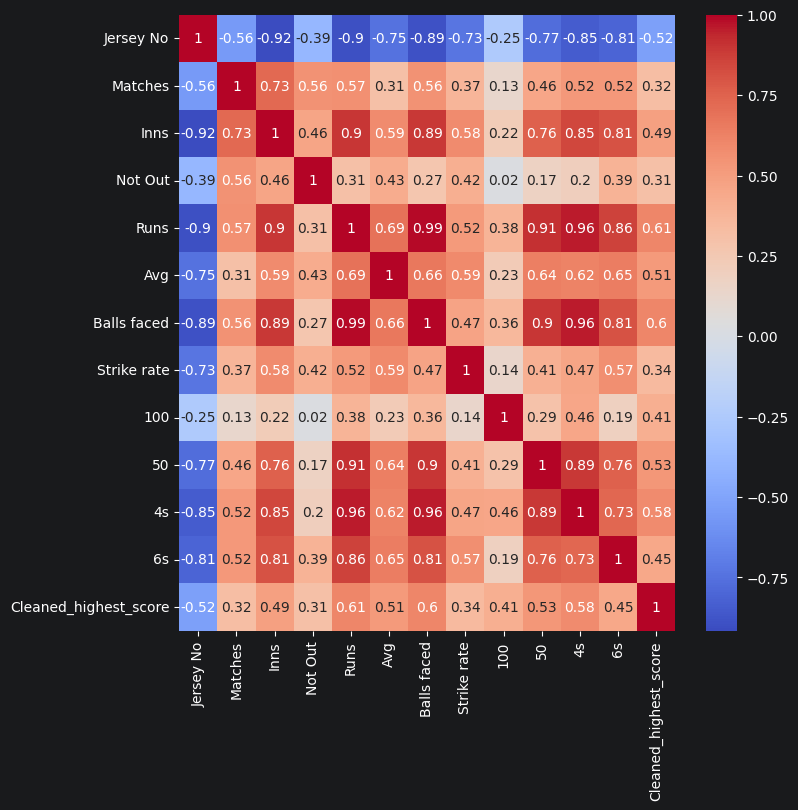

In [137]:
numeric_data = df.select_dtypes(include='number')
correlation = numeric_data.corr()
plt.figure(figsize=(8,8))
sns.heatmap(correlation, annot=True, fmt='.2g',cmap='coolwarm')

In [138]:
#Q8. Check the list of players who has an average greater than 50 as well strike rate above 125. Print player name, average and strike rate.

In [139]:
Q8 = df[(df['Avg']> 50) &(df['Strike rate']>125)]
print(Q8[['Player','Avg','Strike rate']])

             Player     Avg  Strike rate
0          KL Rahul   55.83       129.34
4      Ishan Kishan   57.33       145.76
31   Kieron Pollard   53.60       191.42
36  Wriddhiman Saha   71.33       139.86
57     Deepak Hooda  101.00       142.25
60       Tom Curran   83.00       133.87


In [140]:
#Q9. Please check the list of players who has an average greater than 40 and balls faced above 100. Print player name, average and balls faced.



In [141]:
Q9 = df[(df['Avg']>40) &(df['Balls faced'] > 100)]
print(Q9[['Player','Avg','Balls faced']])

             Player    Avg  Balls faced
0          KL Rahul  55.83          518
1    Shikhar Dhawan  44.14          427
4      Ishan Kishan  57.33          354
8       Virat Kohli  42.36          384
9      ABD Villiers  45.40          286
10    Faf Duplessis  40.81          319
14      Eoin Morgan  41.80          302
24  Kane Williamson  45.28          237
27      Chris Gayle  41.14          210
28       Ben Stokes  40.71          200
31   Kieron Pollard  53.60          140
32    Rahul Tewatia  42.50          183
33  Ravindra Jadeja  46.40          135
36  Wriddhiman Saha  71.33          153
37  Ruturaj Gaikwad  51.00          169


In [142]:
#Q10. Players who scored atleast one century in this season. Create visualization.



            Player  100
0         KL Rahul    1
1   Shikhar Dhawan    2
13  Mayank Agarwal    1
28      Ben Stokes    1


<Axes: xlabel='Player', ylabel='100'>

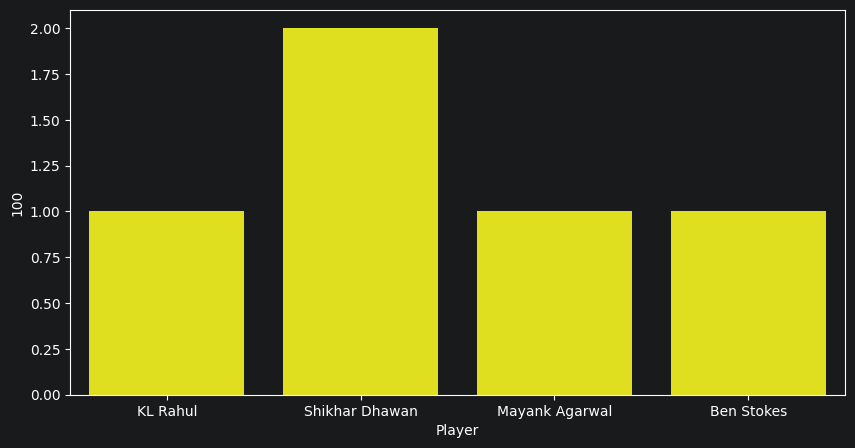

In [143]:
century_player = df[df[100] >= 1]
print(century_player[['Player',100]])
plt.figure(figsize=(10,5))
sns.barplot(data=century_player, x='Player', y=100,color='yellow')

In [144]:
#Q11. Players who scored atleast 4 half centuries in this season.

In [145]:
Q11 = df[df[50]>= 4]
print(Q11[['Player',50]])

              Player  50
0           KL Rahul   5
1     Shikhar Dhawan   4
2       David Warner   4
4       Ishan Kishan   4
5       Quinton Kock   4
6   Suryakumar Yadav   4
7   Devdutt Padikkal   5
9       ABD Villiers   5
10     Faf Duplessis   4


In [146]:
#Q12. Check the list of players who hit more than 45 boundaries and more than 10 sixes in this season.


In [153]:
Q12 = df[(df['4s']> 45) & (df['6s'] > 10)]
print(Q12[['Player','4s','6s']])

             Player  4s  6s
0          KL Rahul  58  23
1    Shikhar Dhawan  67  12
2      David Warner  52  14
5      Quinton Kock  46  22
6  Suryakumar Yadav  61  11


In [ ]:
#Q13. Plot a histogram of number of matches played in a season by players.

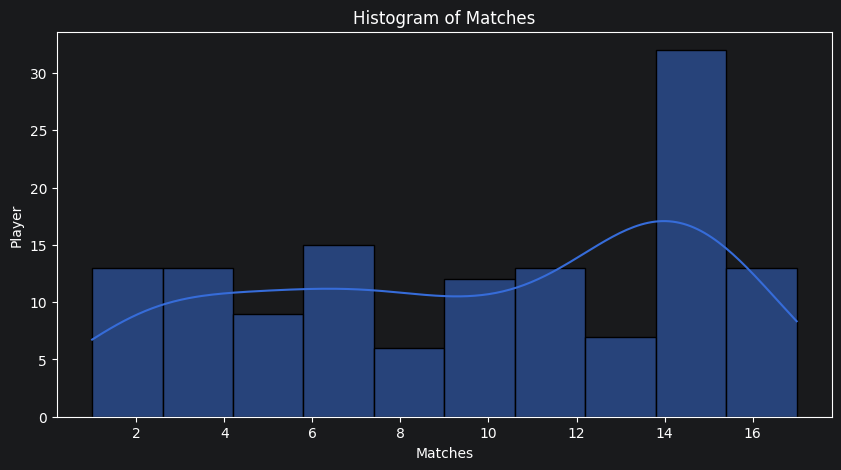

In [157]:
plt.figure(figsize=(10,5))
sns.histplot(data = df,x = 'Matches',bins = 10,kde = True)

plt.title('Histogram of Matches')
plt.xlabel('Matches')
plt.ylabel('Player')
plt.show()

In [ ]:
#Q14. Plot the histogram of balls faced by players.

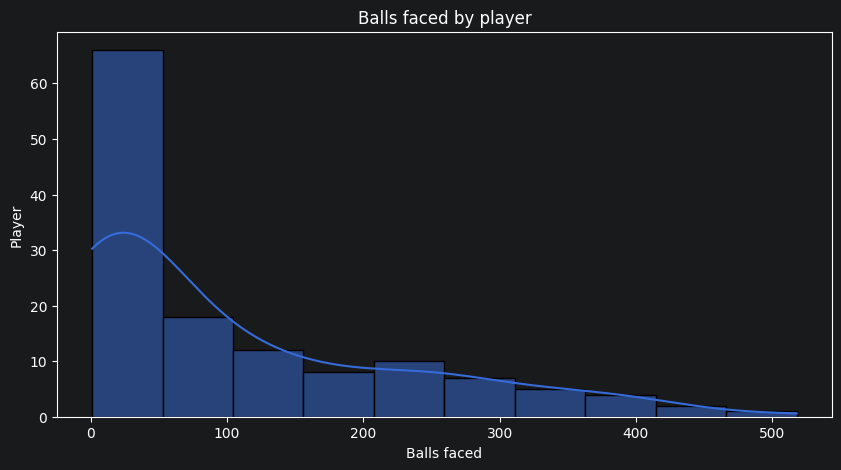

In [158]:
    plt.figure(figsize=(10,5))
sns.histplot(data = df,x = 'Balls faced',bins = 10,kde = True)
plt.title('Balls faced by player')
plt.xlabel('Balls faced')
plt.ylabel('Player')
plt.show()

In [ ]:
#Q15. Top 12 players with most runs in a season.

In [165]:
print(df[['Player','Runs']].head(12))

              Player  Runs
0           KL Rahul   670
1     Shikhar Dhawan   618
2       David Warner   548
3       Shreyas Iyer   519
4       Ishan Kishan   516
5       Quinton Kock   503
6   Suryakumar Yadav   480
7   Devdutt Padikkal   473
8        Virat Kohli   466
9       ABD Villiers   454
10     Faf Duplessis   449
11      Shubman Gill   440


In [ ]:
#Q16. Print the players who played the match but didn't get the batting.

In [171]:
Q16 = df[df['Matches'] > df['Inns']]
print(Q16['Player'].head())

4         Ishan Kishan
6     Suryakumar Yadav
9         ABD Villiers
12       Manish Pandey
16       Ambati Rayudu
Name: Player, dtype: str


In [ ]:
#Q17. Create a new column to show the percentage of total runs scored in 4s and 6s. Then print the top 5 players with maximum percentage.

In [181]:
df['boundary percentage'] = ((df['4s']*4 + df['6s']*6) / df['Runs'])*100
print(df[['Player','boundary percentage']].sort_values('boundary percentage', ascending=False).head())

            Player  boundary percentage
109     Andrew Tye           100.000000
48   Andre Russell            76.923077
74    Chris Morris            76.470588
29   Hardik Pandya            73.309609
47    Sunil Narine            72.727273


In [ ]:
#Q18. Print the players with top 5 Not out percentages (Not Out percentage can be calculated as number of Not outs divided by Innings).

In [185]:
df['Not_out_percentage'] = (df['Not Out'] / df['Inns'] *100)
print(df[['Player','Not_out_percentage']].sort_values('Not_out_percentage', ascending=False).head())

              Player  Not_out_percentage
122    Shahbaz Ahmed               100.0
97     Mohammad Nabi               100.0
114      T Natarajan               100.0
116     Rahul Chahar               100.0
113  Dhawal Kulkarni               100.0


In [ ]:
#Q19. Create visualization of top 10 players with highest number of sixes.

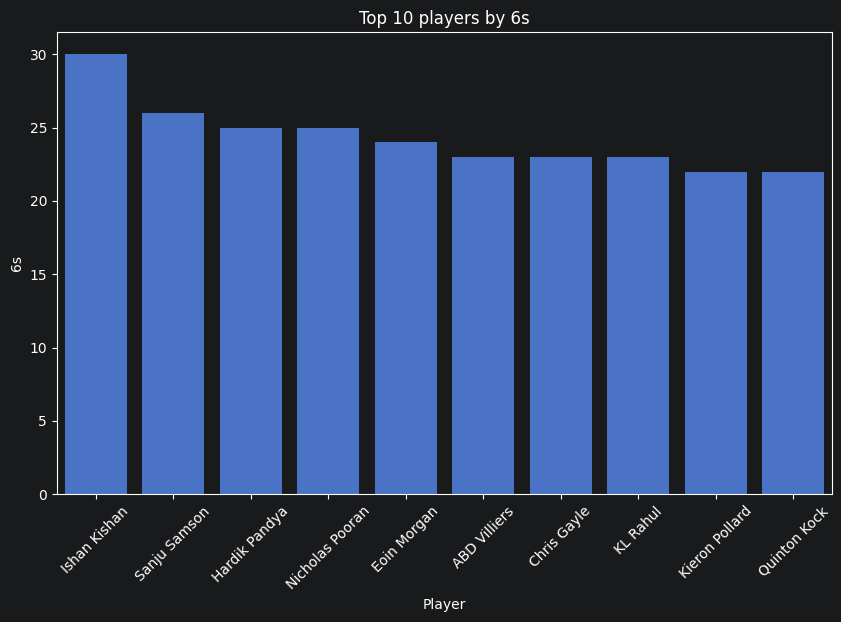

In [190]:
top_10 = df.sort_values('6s', ascending=False).head(10)
plt.figure(figsize=(10,6))
sns.barplot(data = top_10,x='Player',y='6s')
plt.title('Top 10 players by 6s')
plt.xlabel('Player')
plt.ylabel('6s')
plt.xticks(rotation=45)
plt.show()

In [ ]:
#Q20. Scatter plot of runs scored by a player v/s balls faced in a season. Then find the relationship between these 2 variables.

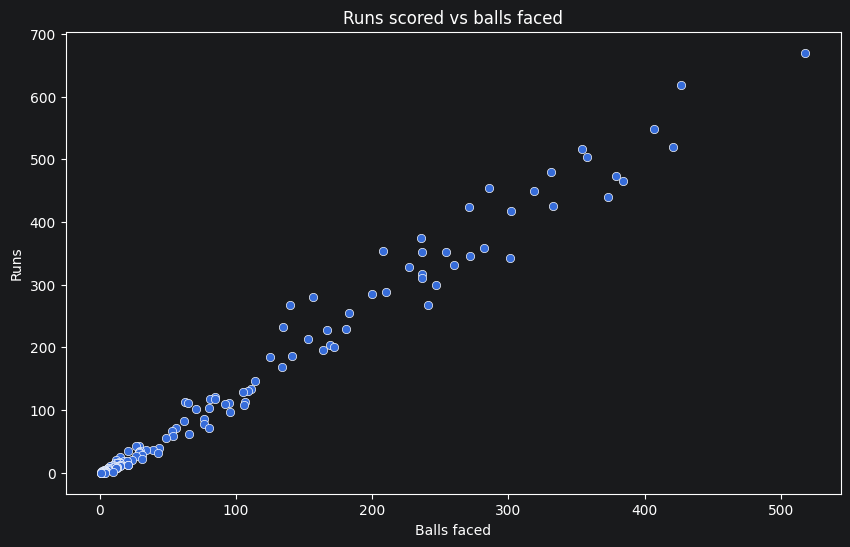

In [192]:
plt.figure(figsize=(10,6))
sns.scatterplot(data = df , x= 'Balls faced' , y = 'Runs')
plt.title('Runs scored vs balls faced')
plt.xlabel('Balls faced')
plt.ylabel('Runs')
plt.show()